#  Statistiek week 1

## Data importeren

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_excel('Data_Statistiek.xlsx')
data

,Observatie ID,Studiejaar,Cursuscode,Motivatiecijfer (1-10),Waardering voor de Cursus (1-5),Geslacht,Totaal Aantal Fouten in Praktijktoets
0,101,1,STAT101,8,4,Vrouw,3
1,102,3,STAT101,6,3,Man,5
2,103,2,STAT101,9,5,Man,1
3,104,1,STAT101,5,2,Vrouw,6
4,105,3,STAT101,7,4,Vrouw,2
5,106,2,STAT101,8,5,Man,0
6,107,1,STAT101,4,2,Man,7
7,108,2,STAT101,7,4,Vrouw,3
8,109,3,STAT101,9,5,Vrouw,1
9,110,1,STAT101,6,3,Man,4


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
rel_data_path = "/content/drive/MyDrive/Data_Statistiek.xlsx"

In [ ]:
data = pd.read_excel(rel_data_path)
data

,Observatie ID,Studiejaar,Cursuscode,Motivatiecijfer (1-10),Waardering voor de Cursus (1-5),Geslacht,Totaal Aantal Fouten in Praktijktoets
0,101,1,STAT101,8,4,Vrouw,3
1,102,3,STAT101,6,3,Man,5
2,103,2,STAT101,9,5,Man,1
3,104,1,STAT101,5,2,Vrouw,6
4,105,3,STAT101,7,4,Vrouw,2
5,106,2,STAT101,8,5,Man,0
6,107,1,STAT101,4,2,Man,7
7,108,2,STAT101,7,4,Vrouw,3
8,109,3,STAT101,9,5,Vrouw,1
9,110,1,STAT101,6,3,Man,4


## Allemaal leuke berekeningen & grafieken

In [ ]:
average_rating_per_year = data.groupby('Studiejaar')['Waardering voor de Cursus (1-5)'].mean()
display(average_rating_per_year)

,Waardering voor de Cursus (1-5)
Studiejaar,
1,2.750000
2,4.666667
3,4.000000


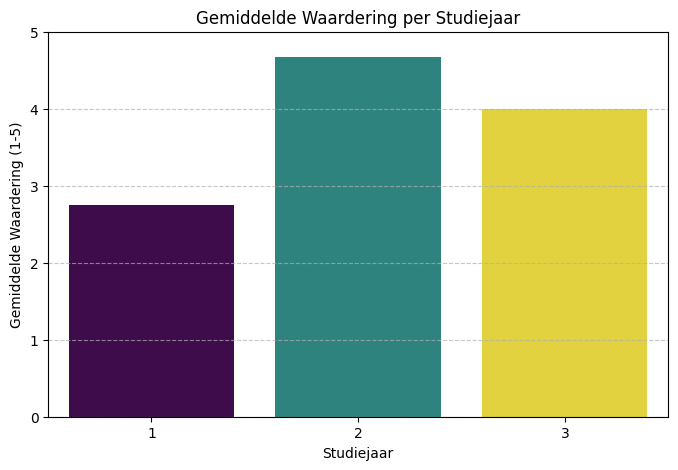

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(x=average_rating_per_year.index, y=average_rating_per_year.values, hue=average_rating_per_year.index, palette='viridis', legend=False)
plt.title('Gemiddelde Waardering per Studiejaar')
plt.xlabel('Studiejaar')
plt.ylabel('Gemiddelde Waardering (1-5)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, 5) # Set y-axis limit from 0 to 5 for rating scale
plt.show()

In [ ]:
correlation = data['Motivatiecijfer (1-10)'].corr(data['Totaal Aantal Fouten in Praktijktoets'])
print(f"Correlatie tussen Motivatiecijfer en Aantal Fouten: {correlation:.2f}")

Correlatie tussen Motivatiecijfer en Aantal Fouten: -0.92


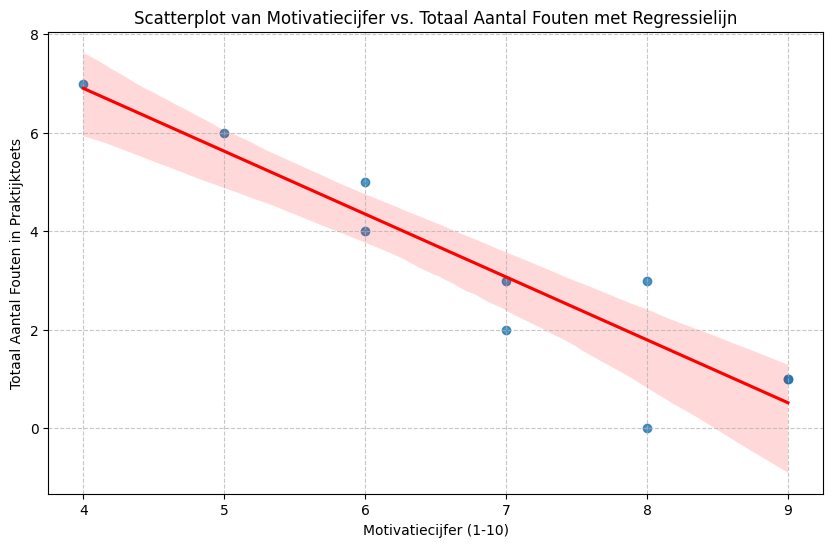

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.regplot(x='Motivatiecijfer (1-10)', y='Totaal Aantal Fouten in Praktijktoets', data=data, scatter_kws={'alpha':0.8}, line_kws={'color':'red'})
plt.title('Scatterplot van Motivatiecijfer vs. Totaal Aantal Fouten met Regressielijn')
plt.xlabel('Motivatiecijfer (1-10)')
plt.ylabel('Totaal Aantal Fouten in Praktijktoets')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
average_errors_per_gender = data.groupby('Geslacht')['Totaal Aantal Fouten in Praktijktoets'].mean()
display(average_errors_per_gender)

,Totaal Aantal Fouten in Praktijktoets
Geslacht,
Man,3.4
Vrouw,3.0


In [ ]:
correlation_jaar_fouten = data['Studiejaar'].corr(data['Totaal Aantal Fouten in Praktijktoets'])
print(f"Correlatie tussen Studiejaar en Aantal Fouten: {correlation_jaar_fouten:.2f}")

Correlatie tussen Studiejaar en Aantal Fouten: -0.49


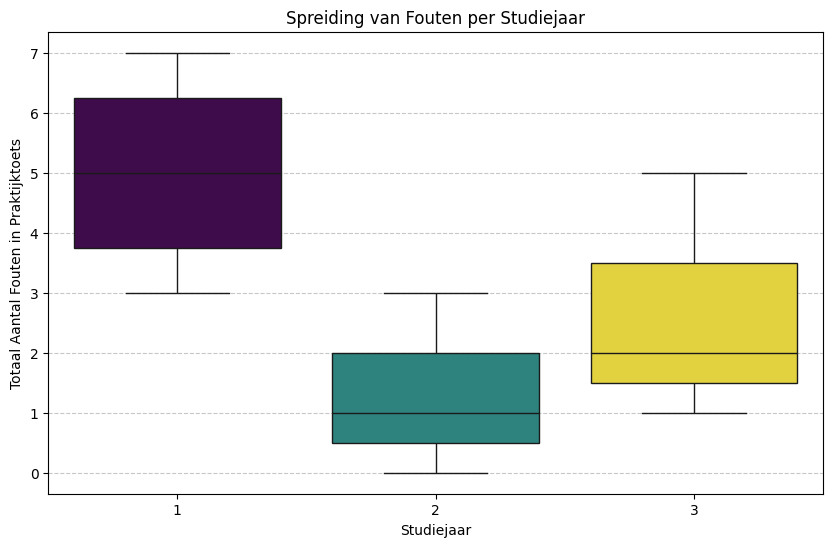

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Studiejaar', y='Totaal Aantal Fouten in Praktijktoets', data=data, palette='viridis', hue='Studiejaar', legend=False)
plt.title('Spreiding van Fouten per Studiejaar')
plt.xlabel('Studiejaar')
plt.ylabel('Totaal Aantal Fouten in Praktijktoets')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
from scipy import stats

# Filter de data voor mannen en vrouwen
errors_man = data[data['Geslacht'] == 'Man']['Totaal Aantal Fouten in Praktijktoets']
errors_vrouw = data[data['Geslacht'] == 'Vrouw']['Totaal Aantal Fouten in Praktijktoets']

# Voer de onafhankelijke samples t-test uit
t_statistic, p_value = stats.ttest_ind(errors_man, errors_vrouw)

print(f"T-statistiek: {t_statistic:.2f}")
print(f"P-waarde: {p_value:.3f}")

# Interpreteer de resultaten (gebruikelijk alpha = 0.05)
if p_value < 0.05:
    print("De p-waarde is kleiner dan 0.05, wat suggereert dat er een significant verschil is in het gemiddelde aantal fouten tussen mannen en vrouwen.")
else:
    print("De p-waarde is groter dan of gelijk aan 0.05, wat suggereert dat er geen significant verschil is in het gemiddelde aantal fouten tussen mannen en vrouwen.")

T-statistiek: 0.26
P-waarde: 0.801
De p-waarde is groter dan of gelijk aan 0.05, wat suggereert dat er geen significant verschil is in het gemiddelde aantal fouten tussen mannen en vrouwen.


In [ ]:
statistical_summary = data.describe()
display(statistical_summary)

,Observatie ID,Studiejaar,Motivatiecijfer (1-10),Waardering voor de Cursus (1-5),Totaal Aantal Fouten in Praktijktoets
count,10.00000,10.000000,10.00000,10.000000,10.000000
mean,105.50000,1.900000,6.90000,3.700000,3.200000
std,3.02765,0.875595,1.66333,1.159502,2.299758
min,101.00000,1.000000,4.00000,2.000000,0.000000
25%,103.25000,1.000000,6.00000,3.000000,1.250000
50%,105.50000,2.000000,7.00000,4.000000,3.000000
75%,107.75000,2.750000,8.00000,4.750000,4.750000
max,110.00000,3.000000,9.00000,5.000000,7.000000


In [ ]:
from scipy import stats

# Haal de waarderingen voor elke studiegroep op
rating_jaar1 = data[data['Studiejaar'] == 1]['Waardering voor de Cursus (1-5)']
rating_jaar2 = data[data['Studiejaar'] == 2]['Waardering voor de Cursus (1-5)']
rating_jaar3 = data[data['Studiejaar'] == 3]['Waardering voor de Cursus (1-5)']

# Voer de one-way ANOVA test uit
f_statistic, p_value = stats.f_oneway(rating_jaar1, rating_jaar2, rating_jaar3)

print(f"F-statistiek: {f_statistic:.2f}")
print(f"P-waarde: {p_value:.3f}")

# Interpreteer de resultaten (gebruikelijk alpha = 0.05)
if p_value < 0.05:
    print("\nDe p-waarde is kleiner dan 0.05, wat suggereert dat er een significant verschil is in de gemiddelde cursuswaardering tussen de studiejaren.")
else:
    print("\nDe p-waarde is groter dan of gelijk aan 0.05, wat suggereert dat er geen significant verschil is in de gemiddelde cursuswaardering tussen de studiejaren.")

F-statistiek: 4.32
P-waarde: 0.060

De p-waarde is groter dan of gelijk aan 0.05, wat suggereert dat er geen significant verschil is in de gemiddelde cursuswaardering tussen de studiejaren.


# Statistiek week 4

## Data importeren

In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

In [ ]:
rel_data_path = "/content/drive/MyDrive/Creditcardtransacties_RZ.xlsx"

In [ ]:
creditcard_transacties = pd.read_excel(rel_data_path)
creditcard_transacties

,TransactieID,Datum,Bedrag (€),Tijdstip,Locatie,Bedrag_Categorie,Aankoopfrequentie,Afstand_van_huis (km)
0,T001,2024-01-01,45.50,14:30:00,Amsterdam,2,3,5.2
1,T002,2024-01-01,125.00,09:15:00,Rotterdam,3,2,12.8
2,T003,2024-01-01,15.75,19:45:00,Utrecht,1,5,8.3
3,T004,2024-01-02,2300.00,02:15:00,Milaan,5,1,1850.0
4,T005,2024-01-02,67.30,11:20:00,Den Haag,2,4,15.6
5,T006,2024-01-02,89.99,16:45:00,Amsterdam,3,3,5.1
6,T007,2024-01-03,34.20,13:10:00,Rotterdam,1,6,13.1
7,T008,2024-01-03,156.75,20:30:00,Utrecht,3,2,8.5
8,T009,2024-01-03,12.50,08:45:00,Amsterdam,1,7,5.0
9,T010,2024-01-04,450.00,23:55:00,Barcelona,4,1,1200.0


## Z-score

In [ ]:
from scipy.stats import zscore

# Calculate Z-scores for 'Bedrag (€)'
creditcard_transacties['Bedrag_Z_score'] = zscore(creditcard_transacties['Bedrag (€)'])

# Define a threshold for outliers (e.g., Z-score > 2 or < -2)
# The choice of threshold depends on the context and desired sensitivity.
z_score_threshold = 2.0

# Identify outliers
outliers_z_score = creditcard_transacties[
    (creditcard_transacties['Bedrag_Z_score'].abs() > z_score_threshold)
].copy()

print(f"Transacties geïdentificeerd als uitschieters op basis van een Z-score > {z_score_threshold} of < -{z_score_threshold}:")
display(outliers_z_score[['TransactieID', 'Bedrag (€)', 'Bedrag_Z_score', 'Locatie']])

Transacties geïdentificeerd als uitschieters op basis van een Z-score > 2.0 of < -2.0:


,TransactieID,Bedrag (€),Bedrag_Z_score,Locatie
3,T004,2300.0,3.782737,Milaan
19,T020,1500.0,2.280128,Parijs


## Dixon's Q-test
Dixon's Q-test is a statistical test used to identify outliers in small data sets (typically N=3-30). It is based on the ratio of the difference between an outlier and its nearest neighbor to the range of the data. A higher Q-value suggests that the extreme value is more likely to be an outlier. To determine if a value is indeed an outlier, the calculated Q-value is compared to a critical Q-value from a table, which depends on the sample size and desired significance level.

In the following code, we will calculate the Q-statistic for the minimum and maximum values in the 'Bedrag (€)' column. You would then compare these calculated Q-statistics to a Dixon's Q critical value table for your specific sample size to determine if they are considered outliers.

In [ ]:
import numpy as np

def calculate_dixon_q(data_series):
    """
    Calculates the Dixon's Q statistic for potential outliers (min and max).
    Assumes a sorted series for calculation.

    Args:
        data_series (pd.Series or list): The data to analyze.

    Returns:
        tuple: (Q_min, Q_max) for the most extreme values, or (None, None) if data is too small.
    """
    sorted_data = np.sort(data_series.values if isinstance(data_series, pd.Series) else data_series)
    n = len(sorted_data)

    if n < 3: # Dixon's Q is typically used for n >= 3
        print("Dixon's Q-test requires at least 3 data points.")
        return None, None

    # Q for the smallest value (Q10)
    # Q10 = (x2 - x1) / (xn - x1)
    q_min = (sorted_data[1] - sorted_data[0]) / (sorted_data[n-1] - sorted_data[0])

    # Q for the largest value (Qnn-1)
    # Qnn-1 = (xn - xn-1) / (xn - x1)
    q_max = (sorted_data[n-1] - sorted_data[n-2]) / (sorted_data[n-1] - sorted_data[0])

    return q_min, q_max

# Extract the 'Bedrag (€)' column
bedrag_data = creditcard_transacties['Bedrag (€)']

# Calculate Dixon Q-scores
q_min_bedrag, q_max_bedrag = calculate_dixon_q(bedrag_data)

print(f"Dixon's Q-statistic for smallest value ('Bedrag (€)'): {q_min_bedrag:.3f}")
print(f"Dixon's Q-statistic for largest value ('Bedrag (€)'): {q_max_bedrag:.3f}")

# Display the sorted data to easily check potential outliers
print("\nSorted 'Bedrag (€)' values:")
display(bedrag_data.sort_values().reset_index(drop=True))


Dixon's Q-statistic for smallest value ('Bedrag (€)'): 0.001
Dixon's Q-statistic for largest value ('Bedrag (€)'): 0.348

Sorted 'Bedrag (€)' values:


,Bedrag (€)
0,3.50
1,5.95
2,10.90
3,12.50
4,15.75
5,18.25
6,22.10
7,33.75
8,34.20
9,45.50


### Boxplot Bedrag

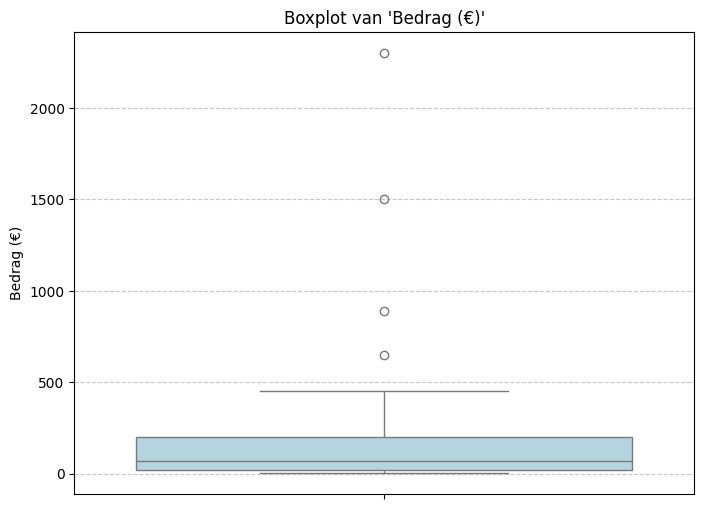

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=creditcard_transacties['Bedrag (€)'], color='lightblue')
plt.title('Boxplot van \'Bedrag (€)\'')
plt.ylabel('Bedrag (€)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Mahalanobis Afstand

De Mahalanobis-afstand is een nuttige maatstaf voor het identificeren van uitschieters in een multidimensionale dataset. In tegenstelling tot de Euclidische afstand, houdt de Mahalanobis-afstand rekening met de correlaties tussen de variabelen en de schaalverschillen. Dit betekent dat het een datapunt als 'verder weg' kan beschouwen als het afwijkt van de verwachte verdeling van de data, zelfs als het Euclidisch gezien niet extreem ver weg is.

In [ ]:
import numpy as np
from scipy.spatial.distance import mahalanobis

# Selecteer de numerieke kolommen voor de berekening
selected_columns = ['Bedrag (€)', 'Afstand_van_huis (km)', 'Aankoopfrequentie']
X = creditcard_transacties[selected_columns].values

# Bereken de inverse van de covariantiematrix
cov_matrix = np.cov(X, rowvar=False) # rowvar=False betekent dat kolommen variabelen zijn
inv_cov_matrix = np.linalg.inv(cov_matrix)

# Bereken de centroid (gemiddelde) van de data
centroid = np.mean(X, axis=0)

# Bereken de Mahalanobis-afstand voor elke rij
mahalanobis_distances = []
for i in range(X.shape[0]):
    distance = mahalanobis(X[i], centroid, inv_cov_matrix)
    mahalanobis_distances.append(distance)

# Voeg de afstanden toe als een nieuwe kolom aan de DataFrame
creditcard_transacties['Mahalanobis_Afstand'] = mahalanobis_distances

# Toon de transacties gesorteerd op Mahalanobis-afstand (om de potentiële uitschieters bovenaan te zien)
display(creditcard_transacties.sort_values(by='Mahalanobis_Afstand', ascending=False).head())


,TransactieID,Datum,Bedrag (€),Tijdstip,Locatie,Bedrag_Categorie,Aankoopfrequentie,Afstand_van_huis (km),Bedrag_Z_score,Mahalanobis_Afstand
24,T025,2024-01-11,650.0,19:20:00,New York,5,1,5800.0,0.683606,4.697838
3,T004,2024-01-02,2300.0,02:15:00,Milaan,5,1,1850.0,3.782737,3.855308
23,T024,2024-01-11,10.9,08:00:00,Amsterdam,1,10,5.3,-0.516791,2.529772
19,T020,2024-01-09,1500.0,14:00:00,Parijs,5,1,500.0,2.280128,2.456149
18,T019,2024-01-08,3.5,09:55:00,Amsterdam,1,9,4.9,-0.530690,2.072664


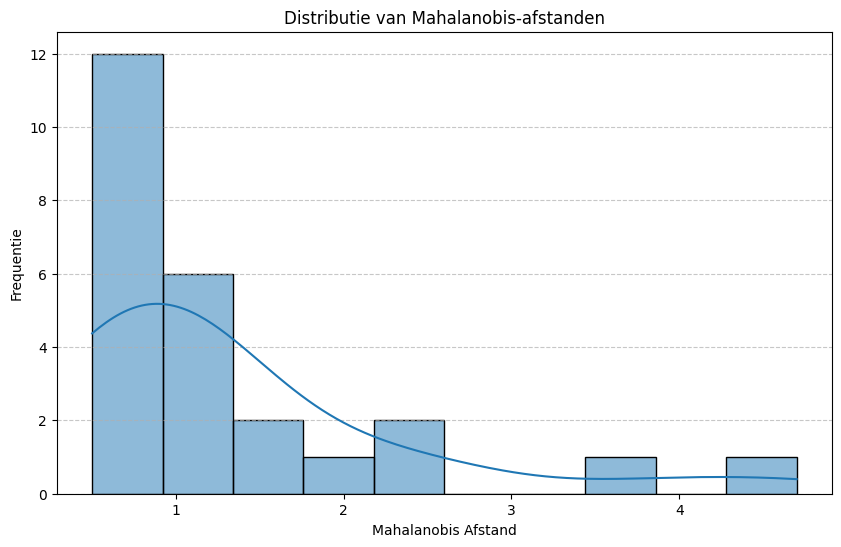

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(creditcard_transacties['Mahalanobis_Afstand'], kde=True, bins=10)
plt.title('Distributie van Mahalanobis-afstanden')
plt.xlabel('Mahalanobis Afstand')
plt.ylabel('Frequentie')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Correlatieanalyse

We zullen de correlaties tussen de numerieke variabelen in de `creditcard_transacties` dataset onderzoeken. Een correlatiematrix geeft de correlatiecoëfficiënten weer tussen alle paren van variabelen. Waarden dicht bij 1 of -1 duiden op een sterke positieve of negatieve lineaire relatie, terwijl waarden dicht bij 0 een zwakke of geen lineaire relatie suggereren.

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Selecteer de numerieke kolommen voor correlatieanalyse
numerical_columns = ['Bedrag (€)', 'Afstand_van_huis (km)', 'Aankoopfrequentie', 'Mahalanobis_Afstand']
correlation_matrix = creditcard_transacties[numerical_columns].corr()

print("Correlatiematrix:")
display(correlation_matrix)

Correlatiematrix:


,Bedrag (€),Afstand_van_huis (km),Aankoopfrequentie,Mahalanobis_Afstand
Bedrag (€),1.000000,0.442031,-0.535445,0.653811
Afstand_van_huis (km),0.442031,1.000000,-0.385154,0.797737
Aankoopfrequentie,-0.535445,-0.385154,1.000000,-0.153769
Mahalanobis_Afstand,0.653811,0.797737,-0.153769,1.000000


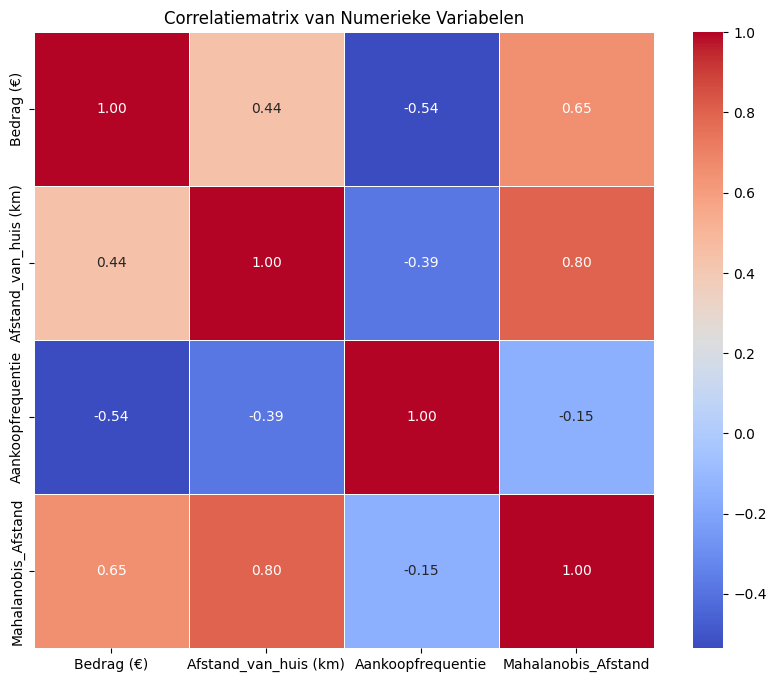

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlatiematrix van Numerieke Variabelen')
plt.show()

### Interpretatie van de Correlatiematrix

De heatmap hierboven visualiseert de correlatie tussen de geselecteerde numerieke variabelen. Hier zijn enkele observaties:

- **'Bedrag (€)' en 'Afstand_van_huis (km)'**: Een positieve correlatie suggereert dat hogere transactiebedragen vaak samengaan met grotere afstanden van huis. Dit kan wijzen op transacties die plaatsvinden tijdens reizen.
- **'Aankoopfrequentie'**: De correlaties met 'Bedrag (€)' en 'Afstand_van_huis (km)' lijken zwak, wat aangeeft dat de frequentie van aankopen niet sterk lineair gerelateerd is aan het bedrag of de afstand.
- **'Mahalanobis_Afstand'**: Deze variabele toont de multivariabele afstand van een datapunt tot het centrum van de gegevens. Een hogere Mahalanobis-afstand correleert zoals verwacht met de 'Afstand_van_huis (km)' en 'Bedrag (€)', aangezien extreme waarden in deze dimensies de Mahalanobis-afstand zullen vergroten. Dit bevestigt dat de Mahalanobis-afstand goed de multivariabele uitschieters identificeert.

### Spreidingsdiagram Bedrag vs Afstand

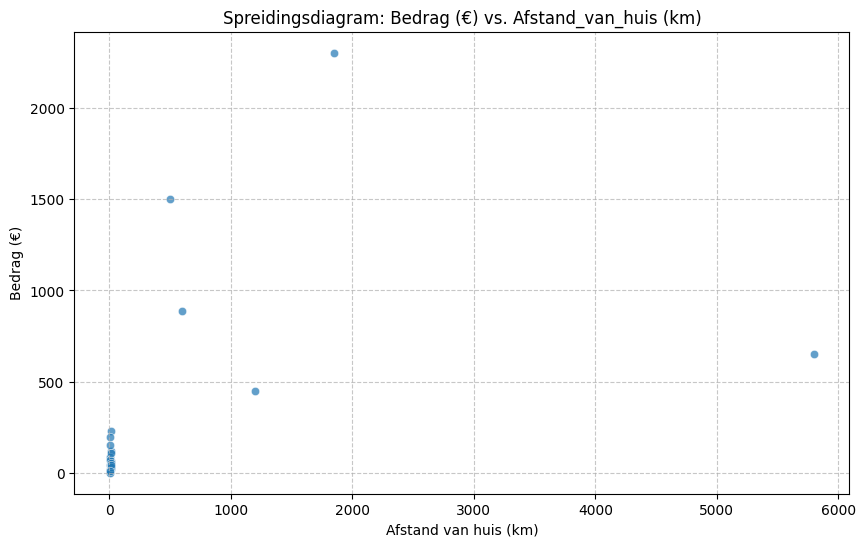

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Afstand_van_huis (km)', y='Bedrag (€)', data=creditcard_transacties, alpha=0.7)
plt.title('Spreidingsdiagram: Bedrag (€) vs. Afstand_van_huis (km)')
plt.xlabel('Afstand van huis (km)')
plt.ylabel('Bedrag (€)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()